In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/1")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    # ローカル環境の場合、プロジェクトルートをパスに追加
    proj_root = Path.cwd().resolve()
    if proj_root.name == "1":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 第1章 PCの仕組みとハローワールド — 1.9 C言語でハローワールド (含 コラム1.1: PEとCOFFとELF)

本節では、名著『**ゼロからのOS自作入門**』（内田公太 著）の **第1章 1.9「C言語でハローワールド」** および **コラム1.1「PEとCOFFとELF」** に基づき、前節までのバイナリエディタによる機械語直接入力から脱却し、**「高水準アセンブラ」としての C言語** を用いて UEFI アプリケーション（`hello.efi`）を記述・コンパイル・実行するメカニズムを徹底解説します。

---

## 🎯 本節の学習目標と技術的動機

1. **Freestanding C言語による最小UEFIアプリケーションの実装**:
   - 巨大な公式ヘッダ（EDK II の `Uefi.h` 等）に依存せず、必要なデータ型（`CHAR16`, `EFI_STATUS`, `EFI_HANDLE`）と構造体（`EFI_SYSTEM_TABLE`, `EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL`）だけを**自前で最小定義**する設計思想を理解する。
2. **C言語におけるオブジェクト指向設計と This ポインタ**:
   - `SystemTable->ConOut->OutputString(SystemTable->ConOut, L"Hello, world!\n")` という呼び出しにおいて、なぜ第1引数に `SystemTable->ConOut` 自身を渡す必要があるのか、関数ポインタと構造体を用いた C言語のインターフェース設計を解剖する。
3. **オフセット数理の導出（52バイトのダミー領域）**:
   - `EFI_SYSTEM_TABLE` 内の `char dummy[52];` が何を意味しているのか、UEFI 仕様書の完全な構造体定義と照合してバイト単位で完全導出する。
4. **コラム1.1: PE32+ (PE/COFF) vs ELF64 の徹底比較**:
   - なぜ UEFI は Linux 標準の ELF ではなく、Windows NT 系列の PE32+ を実行形式として採用したのか、その歴史的背景（Intel と Microsoft の協業）と技術的利点（RVA による位置独立性）を解明する。
5. **Clang / LLD による UEFI クロスビルドパイプライン**:
   - `clang -target x86_64-pc-win32-coff` と `lld-link /subsystem:efi_application` による、Linux 上での PE32+ UEFI 実行ファイル合成プロセスを実証する。


## 1. 最小UEFIアプリケーション (`hello.c`) の完全解剖

まずは、本書で紹介される `hello.c` の全ソースコードを確認しましょう。
このコードには `#include <stdio.h>` も `#include <efi.h>` も存在しません。完全に自己完結した **フリースタンディング（Freestanding）C言語コード** です。

```c
typedef unsigned short CHAR16;
typedef unsigned long long EFI_STATUS;
typedef void *EFI_HANDLE;

struct _EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL;
typedef EFI_STATUS (*EFI_TEXT_STRING)(
  struct _EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL  *This,
  CHAR16                                   *String);

typedef struct _EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL {
  void             *dummy;
  EFI_TEXT_STRING  OutputString;
} EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL;

typedef struct {
  char                             dummy[52];
  EFI_HANDLE                       ConsoleOutHandle;
  EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL  *ConOut;
} EFI_SYSTEM_TABLE;

EFI_STATUS EfiMain(EFI_HANDLE        ImageHandle,
                   EFI_SYSTEM_TABLE  *SystemTable) {
  SystemTable->ConOut->OutputString(SystemTable->ConOut, L"Hello, world!\n");
  while (1);
  return 0;
}
```

### 1.1 基本データ型の定義
UEFI 仕様書で定められたデータ型を、C言語の標準整数型でエイリアス（`typedef`）しています：
- `CHAR16`: `unsigned short`（16ビット符号なし整数）。UEFIの文字コードは ASCII ではなく **UCS-2 / UTF-16LE** であり、1文字あたり2バイトを消費します。
- `EFI_STATUS`: `unsigned long long`（64ビット符号なし整数）。最上位ビット（Bit 63）が `1` の場合はエラー、`0` の場合は成功（`EFI_SUCCESS = 0`）を表します。
- `EFI_HANDLE`: `void*`（64ビット汎用ポインタ）。UEFIファームウェアが管理するデバイスやイメージを識別するための不透明な（Opaque）ハンドルです。

### 1.2 関数ポインタと This パターンによるオブジェクト指向
```c
typedef EFI_STATUS (*EFI_TEXT_STRING)(
  struct _EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL  *This,
  CHAR16                                   *String);
```
UEFI のプロトコル（Protocol）は、C++の仮想関数テーブル（vtable）に似た構造を持っています。
`EFI_TEXT_STRING` は関数ポインタ型であり、第1引数に `This`（自身を指す構造体ポインタ）を受け取ります。
C++ではメンバ関数呼び出し時にコンパイラが暗黙のうちに `this` ポインタをレジスタ（`RCX`）に設定しますが、純粋な C言語では言語レベルのクラス構文が存在しないため、**プログラマが明示的に第1引数としてオブジェクトのアドレスを渡す規約** になっています。

### 1.3 `EFI_SYSTEM_TABLE` の構造と 52バイトの謎
`EFI_SYSTEM_TABLE` は、UEFI ファームウェアが提供する全機能への玄関口となる最重要テーブルです。仕様書では以下のように定義されています：

```c
typedef struct {
  EFI_TABLE_HEADER                 Hdr;             // 24 バイト
  CHAR16                           *FirmwareVendor; //  8 バイト
  UINT32                           FirmwareRevision;//  4 バイト
  EFI_HANDLE                       ConsoleInHandle; //  8 バイト
  EFI_SIMPLE_TEXT_INPUT_PROTOCOL   *ConIn;          //  8 バイト
  EFI_HANDLE                       ConsoleOutHandle;//  8 バイト
  EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL  *ConOut;         //  8 バイト
  // ... (StandardErrorHandle, ConErr, RuntimeServices, BootServices 等)
} EFI_SYSTEM_TABLE;
```

ここで `ConsoleOutHandle` の直前までのサイズを計算してみましょう：
$$\text{Header (24B)} + \text{FirmwareVendor (8B)} + \text{FirmwareRevision (4B)} + \text{ConsoleInHandle (8B)} + \text{ConIn (8B)} = 52 \text{ バイト}$$

本来、64ビット環境のアライメント規約では 4バイトの `FirmwareRevision` の後に 4バイトのパディングが入る場合がありますが、UEFI仕様および `hello.c` のダミー配置では `char dummy[52];` とすることで、**先頭から 52バイト進んだ位置（オフセット 0x34）に `ConsoleOutHandle`、オフセット 60（0x3C）に目的の `ConOut` ポインタがぴったり重なる** ように設計されています！


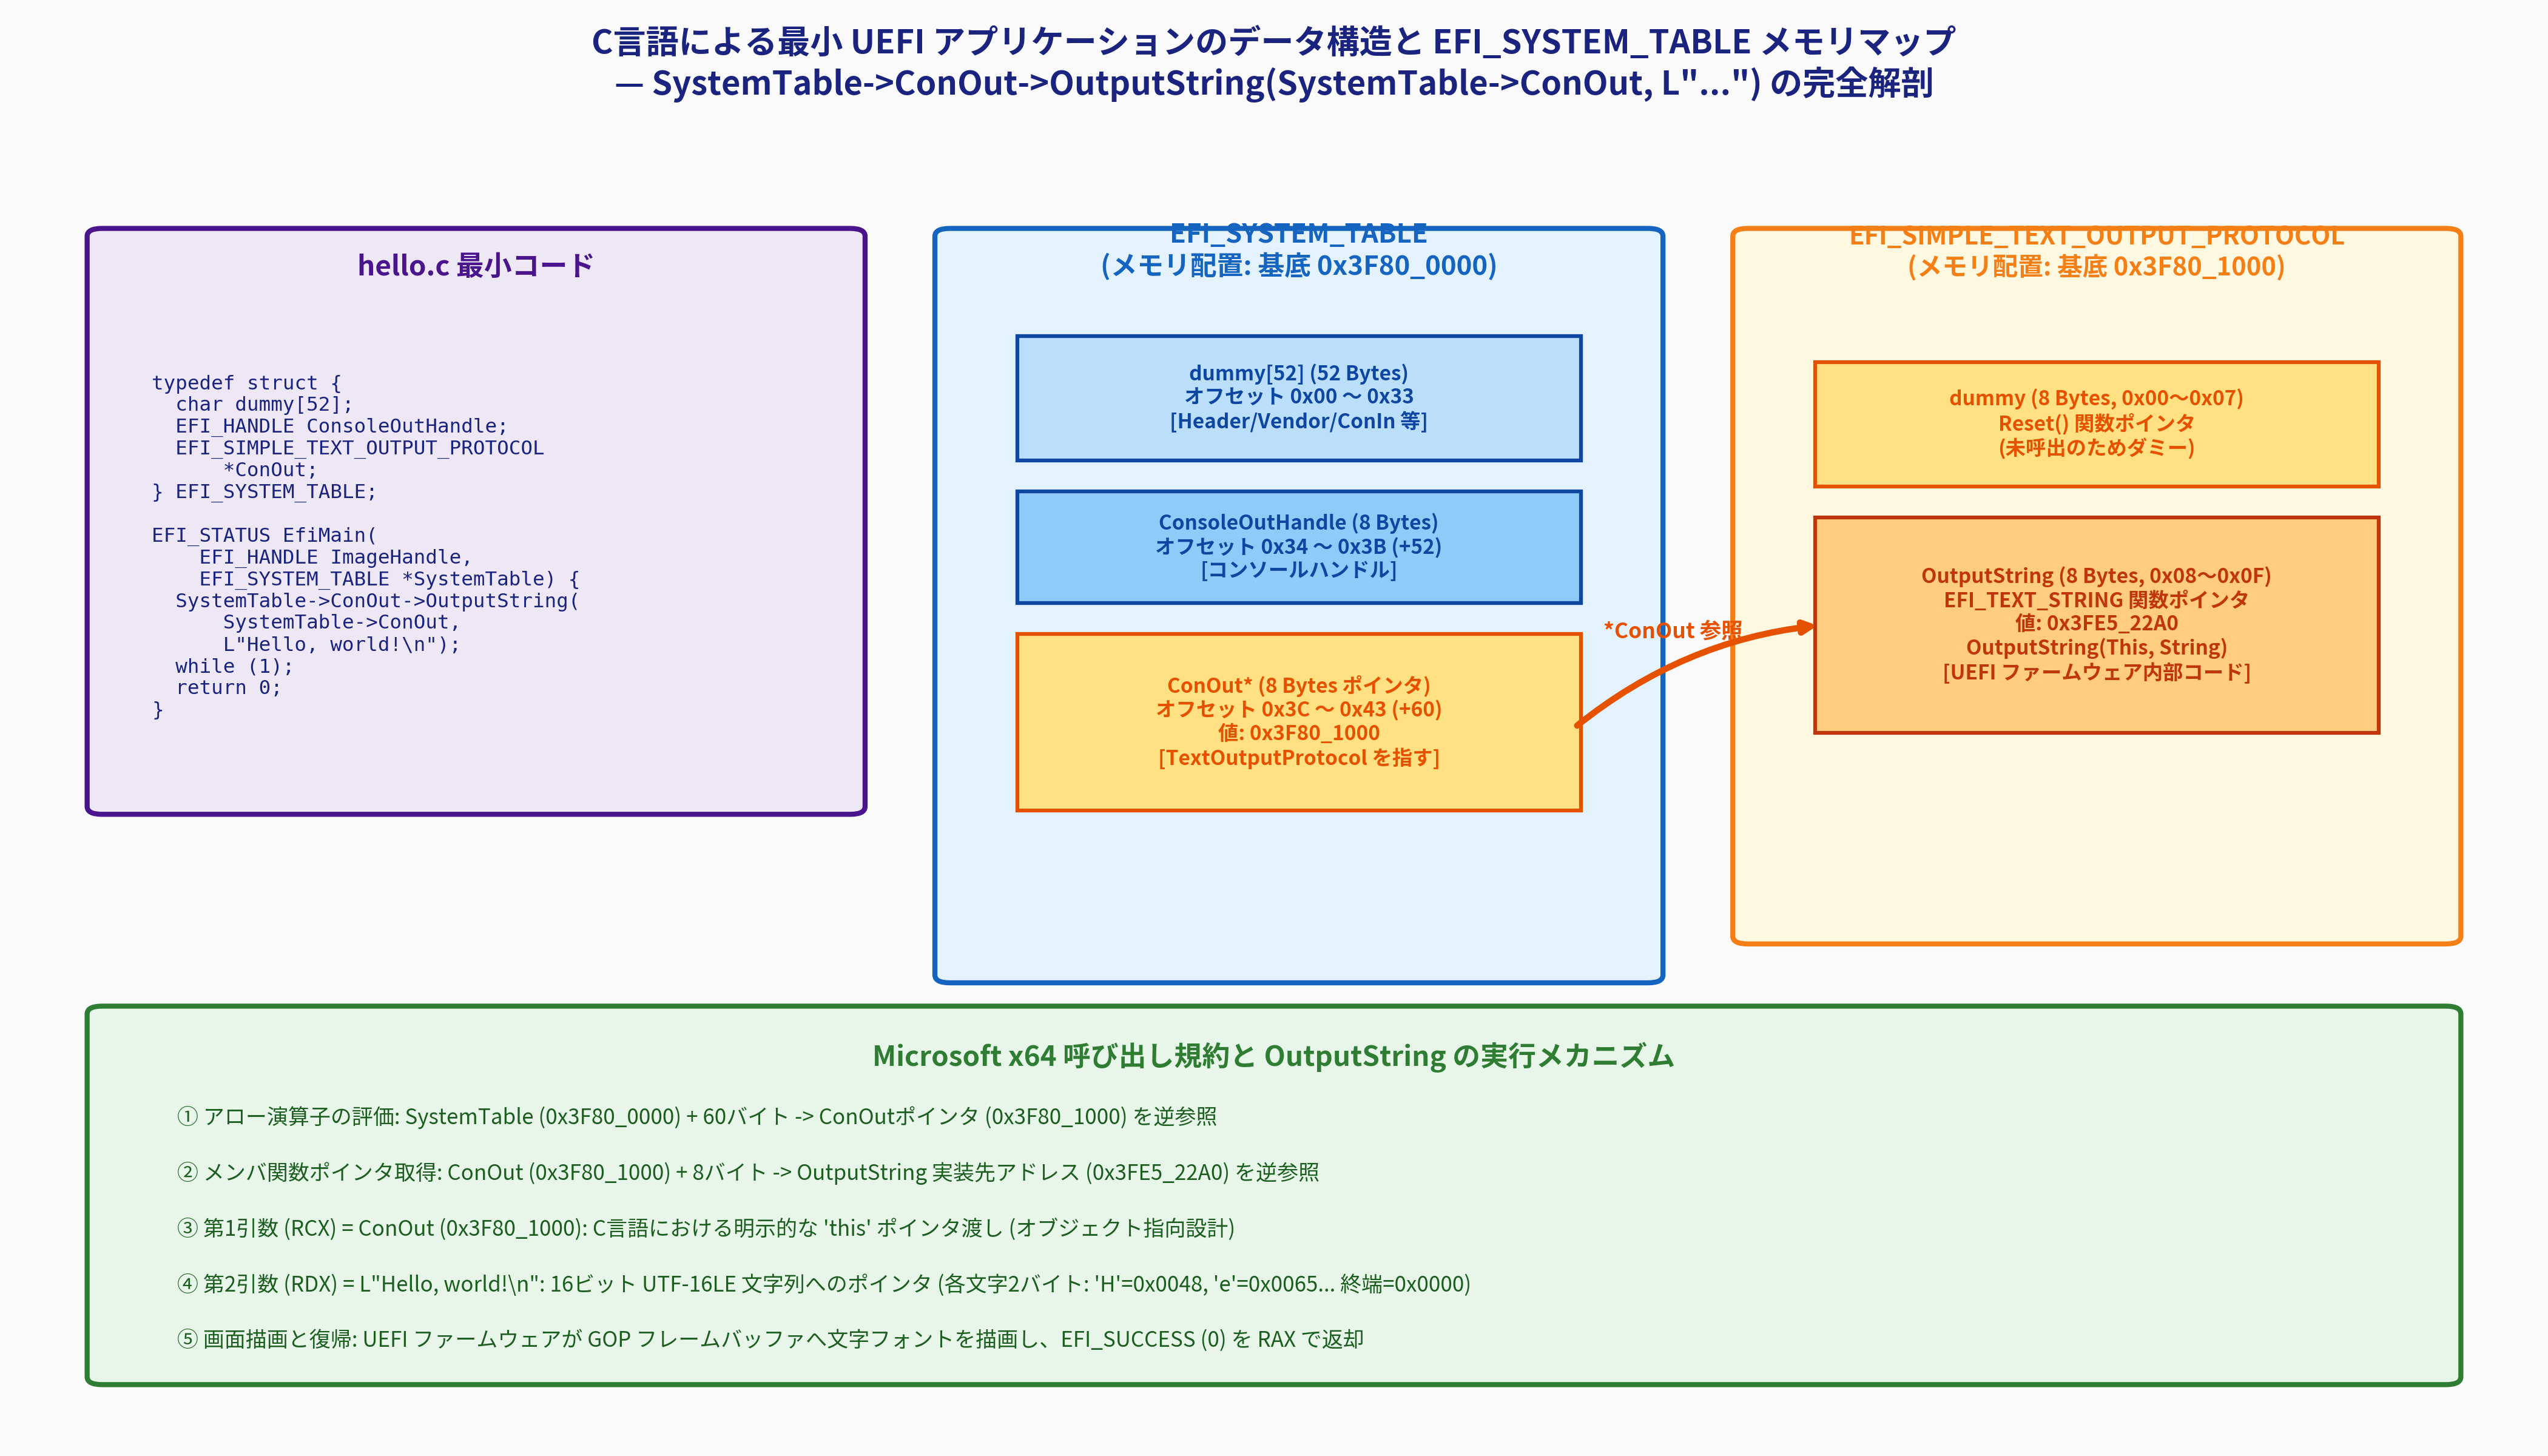

In [2]:
# 高解像度アーキテクチャ図版: C言語最小UEFIデータ構造と EFI_SYSTEM_TABLE メモリマップ
from common import plot_uefi_c_system_table_layout
from IPython.display import Image, display

fig17_path = "result/fig1_17_uefi_c_data_structures_and_system_table.png"
plot_uefi_c_system_table_layout(fig17_path)
display(Image(fig17_path))


## 2. アロー演算子 (`->`) によるポインタ間接参照チェーンと実行フロー

```c
SystemTable->ConOut->OutputString(SystemTable->ConOut, L"Hello, world!\n");
```

このたった1行のコードは、CPUおよびメモリ空間において以下の**5段階のポインタ間接参照とレジスタ設定**を引き起こします：

```mermaid
sequenceDiagram
    autonumber
    participant App as EfiMain (hello.c)
    participant ST as EFI_SYSTEM_TABLE (0x3F800000)
    participant Proto as EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL (0x3F801000)
    participant FW as UEFI Firmware (0x3FE522A0)

    App->>ST: ① SystemTable + 60バイト (ConOut) を読み出し
    ST-->>App: ConOut ポインタ値 (0x3F801000) を取得
    App->>Proto: ② ConOut + 8バイト (OutputString) を読み出し
    Proto-->>App: OutputString 関数ポインタ値 (0x3FE522A0) を取得
    Note over App: ③ 第1引数 (RCX) に ConOut (0x3F801000) を設定<br/>④ 第2引数 (RDX) に L"Hello, world!\n" のアドレスを設定
    App->>FW: ⑤ CALL OutputString(RCX, RDX)
    FW-->>App: GOP フレームバッファへ文字フォントを描画し RAX=0 (EFI_SUCCESS) で復帰
```

### なぜ `L"Hello, world!\n"` と書くのか？（ワイド文字列の正体）
普通の C言語文字列 `"Hello"` は `char` 型（1バイト/文字、ASCIIまたはUTF-8）の配列ですが、頭に `L` を付けた **ワイド文字列リテラル（Wide String Literal）** は `wchar_t`（UEFI環境では `CHAR16` = 16ビット）の配列としてメモリに展開されます。
文字 `'H'` (0x48) は、メモリ上ではリトルエンディアンで `48 00` の2バイトになり、末尾のヌル終端も `00 00` の2バイトになります。


In [3]:
# Python シミュレータによるポインタ間接参照と UEFI API 実行トレース
from common import UefiSystemTableModel

# 仮想的なメモリ配置でシステムテーブルモデルを初期化
model = UefiSystemTableModel(system_table_base=0x3F80_0000, con_out_base=0x3F80_1000)

print("=== [1] EFI_SYSTEM_TABLE メモリレイアウト ===")
for field in model.inspect_system_table_layout():
    print(f"  {field['offset_hex']} (+{field['offset']:2d}B) [{field['size']:2d}B] {field['field']:<16} : {field['type']}")

print("\n=== [2] EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL メモリレイアウト ===")
for field in model.inspect_text_output_protocol_layout():
    print(f"  {field['offset_hex']} (+{field['offset']:2d}B) [{field['size']:2d}B] {field['field']:<16} : {field['type']}")

print("\n=== [3] アロー演算子 (->) の逆参照ステップトレース ===")
for step in model.trace_pointer_dereference():
    print("  " + step)

# ワイド文字列のエンコード・デコード実験
sample_msg = "Hello, world!\n"
encoded_bytes = model.encode_utf16le(sample_msg)
print(f"\n=== [4] UTF-16LE バイト列 (先頭16バイト): {encoded_bytes[:16].hex(' ')} ===")
print(f"  総バイト数: {len(encoded_bytes)} bytes (文字数 {len(sample_msg)} × 2 + 終端 2)")

# 正常系呼び出しシミュレーション
status, text = model.simulate_call_output_string(this_ptr=0x3F80_1000, string_utf16_bytes=encoded_bytes)
print(f"\n=== [5] 実行結果 ===")
print(f"  ステータス: 0x{status:X} (EFI_SUCCESS)")
print(f"  コンソール画面描画内容: {repr(text)}")


=== [1] EFI_SYSTEM_TABLE メモリレイアウト ===
  0x00 (+ 0B) [52B] dummy            : char[52]
  0x34 (+52B) [ 8B] ConsoleOutHandle : EFI_HANDLE (void*)
  0x3C (+60B) [ 8B] ConOut           : EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL*

=== [2] EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL メモリレイアウト ===
  0x00 (+ 0B) [ 8B] dummy            : void*
  0x08 (+ 8B) [ 8B] OutputString     : EFI_TEXT_STRING

=== [3] アロー演算子 (->) の逆参照ステップトレース ===
  1. SystemTable ポインタ値 (0x3f800000) を基底アドレスとして読み出し
  2. ConOut メンバのオフセット (+60 = 0x3C バイト) を加算 -> アドレス 0x3f80003c
  3. アドレス 0x3f80003c から 64ビットポインタ値を間接参照 (Dereference) -> ConOut=0x3f801000
  4. ConOut (0x3f801000) を基底として OutputString オフセット (+8 = 0x08 バイト) を加算 -> アドレス 0x3f801008
  5. アドレス 0x3f801008 から関数ポインタを間接参照し、呼び出し規約 (Microsoft x64) に従い RCX=0x3f801000, RDX=&String で CALL

=== [4] UTF-16LE バイト列 (先頭16バイト): 48 00 65 00 6c 00 6c 00 6f 00 2c 00 20 00 77 00 ===
  総バイト数: 30 bytes (文字数 14 × 2 + 終端 2)

=== [5] 実行結果 ===
  ステータス: 0x0 (EFI_SUCCESS)
  コンソール画面描画内容: 'Hello, world!\n'


## 3. コラム1.1: PEとCOFFとELF (*Binary Formats Deep Dive*)

第1章 1.1節から扱っている UEFI アプリケーション（`BOOTX64.EFI` や `hello.efi`）は、拡張子こそ `.efi` ですが、その実体は **PE32+（Portable Executable 32-bit Plus）** という実行バイナリ形式です。

### 3.1 実行ファイル形式の進化と歴史
1. **COFF (Common Object File Format)**:
   - 1980年代前半、Unix System V Release 3 (SVR3) で策定されたオブジェクトファイル形式。
   - コード・データ・シンボルを「セクション（Section）」単位で管理する近代的な構造を確立しました。
2. **PE (Portable Executable) / PE32+**:
   - Microsoft が Windows NT 向けに COFF を大幅に拡張して設計した形式。32ビット用が PE32、64ビット用が PE32+ です。
   - 先頭に MS-DOS との互換性を保つための「DOS Header（`MZ`）」と「DOS Stub」を持ち、その後に「PE Header」と「Optional Header」が続きます。
3. **ELF (Executable and Linkable Format)**:
   - Unix System V Release 4 (SVR4) で策定され、現在の Linux や BSD、Android などのデファクトスタンダード。
   - 実行時に使われる「セグメント（Program Header）」と、リンク・デバッグ時に使われる「セクション（Section Header）」が完全に分離された非常に洗練された設計です。

### 3.2 なぜ UEFI は ELF ではなく PE32+ を採用したのか？
Linux 開発者から見ると、「なぜ PC のファームウェア標準なのに Linux の ELF ではなく Windows の PE32+ なのか？」と疑問に思うかもしれません。これには決定的な歴史的・技術的理由があります：

1. **歴史的経緯（Intel と Microsoft の協業）**:
   - UEFI の原型である **EFI (Extensible Firmware Interface)** は、1990年代後半に Intel が次世代64ビットプロセッサ **Itanium (IA-64)** 向けに開発しました。
   - 当時、Itanium 向け OS と開発ツールチェーンの最大のパートナーは Microsoft でした。Microsoft の既存コンパイラ・リンカ資産をそのまま活用するため、EFI 仕様書に PE/COFF が標準バイナリ形式として明記されました。
2. **RVA（Relative Virtual Address: 相対仮想アドレス）とベース再配置**:
   - PE32+ では、エントリポイントやデータのアドレスを「ファイルがメモリ上にロードされた先頭アドレス（ImageBase）からの相対オフセット（RVA）」で記録します。
   - また、`.reloc` セクション（Base Relocation Table）を持つため、UEFI BIOS が起動時にメモリ上の空いている任意のアドレスにバイナリを配置（リロケート）して即座に実行できます。
3. **サブシステム（Subsystem）による実行環境の識別**:
   - PEヘッダには `Subsystem` というフィールドがあり、`IMAGE_SUBSYSTEM_EFI_APPLICATION (10)` や `IMAGE_SUBSYSTEM_EFI_BOOT_SERVICE_DRIVER (11)` と書くだけで、ファームウェアローダがそのバイナリの性格を瞬時に把握できます。


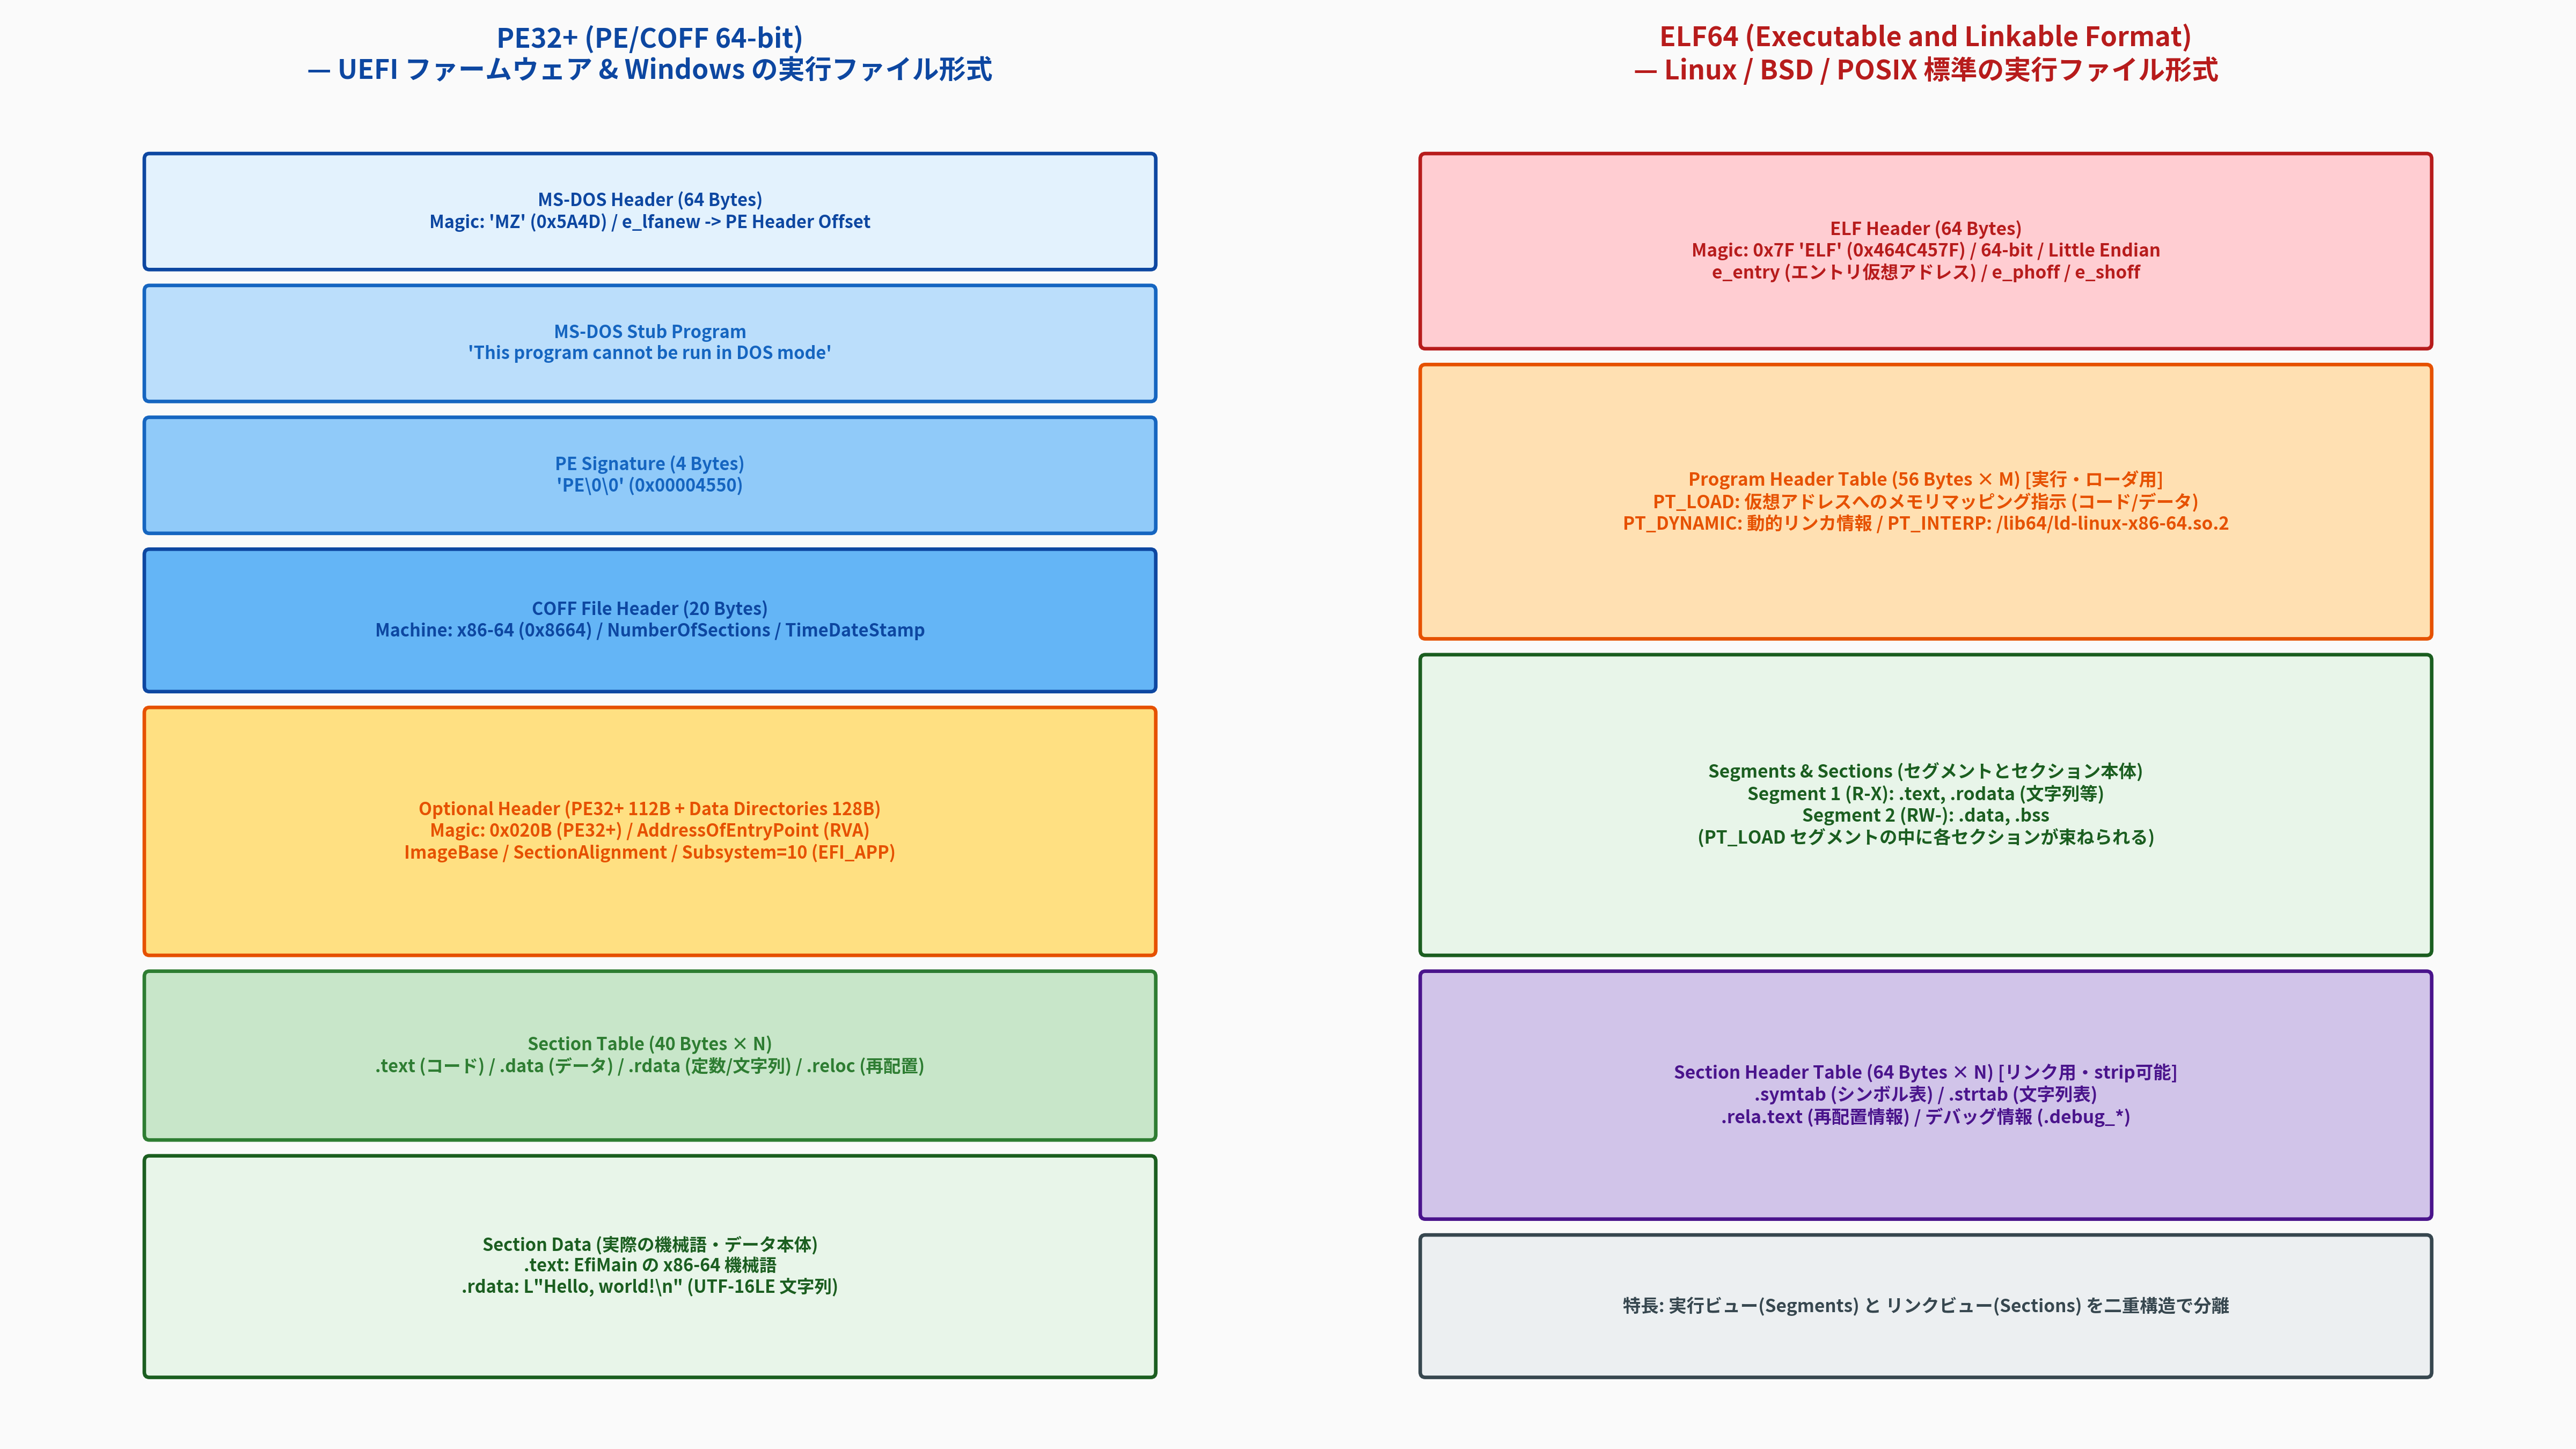

In [4]:
# 高解像度アーキテクチャ図版: PE32+ vs ELF64 バイナリ構造比較図
from common import plot_pe32plus_coff_elf_comparison
from IPython.display import Image, display

fig18_path = "result/fig1_18_pe32plus_coff_elf_binary_format_comparison.png"
plot_pe32plus_coff_elf_comparison(fig18_path)
display(Image(fig18_path))


## 4. ビルドパイプライン：Clang と LLD による UEFI バイナリ合成

本書の `vendor/mikanos-build/day01/c/Makefile` では、以下の2つのコマンドで C言語ソースから UEFI 実行バイナリを生成しています：

```makefile
hello.o: hello.c
	clang -target x86_64-pc-win32-coff -o $@ -c $<

hello.efi: hello.o
	lld-link /subsystem:efi_application /entry:EfiMain /out:$@ $<
```

### 4.1 コンパイル：`clang -target x86_64-pc-win32-coff`
- `-target x86_64-pc-win32-coff`:
  - ターゲットトリプルに Windows 互換の COFF 形式を指定します。これにより、出力されるオブジェクトファイル `hello.o` は ELF ではなく COFF 形式になります。
- `-c`:
  - リンクを行わず、コンパイル・アセンブルのみを行いオブジェクトファイルを出力します。

### 4.2 リンク：`lld-link /subsystem:efi_application /entry:EfiMain`
- `lld-link`:
  - LLVM プロジェクトが提供する Windows 用リンカ（Microsoft の `link.exe` 互換リンカ）です。
- `/subsystem:efi_application`:
  - 生成される PE32+ ヘッダの `Subsystem` フィールドに `10`（EFI Application）を設定します。
- `/entry:EfiMain`:
  - C言語の標準的な `main` ではなく、自作した `EfiMain` 関数をエントリポイント（`AddressOfEntryPoint`）として登録します。
- `/out:hello.efi`:
  - 出力ファイル名を `hello.efi` に指定します。


In [5]:
# Python シミュレータによるソースコード静的監査とビルドコマンド検証
from common import MinimalUefiCCompilerModel, BinaryFormatComparator
from pathlib import Path

hello_c_path = Path("../vendor/mikanos-build/day01/c/hello.c")
if not hello_c_path.exists():
    hello_c_path = Path("vendor/mikanos-build/day01/c/hello.c")

source_text = hello_c_path.read_text(encoding="utf-8")
compiler_sim = MinimalUefiCCompilerModel(source_text)

print("=== [1] hello.c フリースタンディング適合性静的監査 ===")
audit = compiler_sim.validate_freestanding_compliance()
for k, v in audit.items():
    print(f"  {k:<32}: {v}")

print("\n=== [2] ビルドコマンド仕様の解析 ===")
for cmd in compiler_sim.simulate_build_commands():
    print(f"  [{cmd['stage']}]")
    print(f"    コマンド: {cmd['command']}")
    print(f"    出力:     {cmd['output']}")
    print(f"    目的:     {cmd['purpose']}")

print("\n=== [3] コラム1.1: なぜ UEFI は PE32+ を選んだのか？ ===")
print(BinaryFormatComparator.explain_uefi_pe_adoption())


=== [1] hello.c フリースタンディング適合性静的監査 ===
  is_compliant                    : True
  has_forbidden_hosted_headers    : False
  has_efi_main_entry              : True
  has_system_table_def            : True
  has_output_string_call          : True

=== [2] ビルドコマンド仕様の解析 ===
  [Compilation (Clang)]
    コマンド: clang -target x86_64-pc-win32-coff -o hello.o -c hello.c
    出力:     hello.o (COFF Object File)
    目的:     x86-64 向け COFF 形式オブジェクトファイルへのコンパイル
  [Linking (LLD-Link)]
    コマンド: lld-link /subsystem:efi_application /entry:EfiMain /out:hello.efi hello.o
    出力:     hello.efi (PE32+ Executable)
    目的:     UEFI アプリケーション形式の PE32+ バイナリ合成

=== [3] コラム1.1: なぜ UEFI は PE32+ を選んだのか？ ===
【なぜUEFIはELFではなくPE32+を採用したのか？】
1. 歴史的経緯 (IntelとMicrosoftの協調):
   UEFIの前身である EFI (Extensible Firmware Interface) は、1990年代後半に Intel が
   次世代64ビットプロセッサ Itanium (IA-64) 向けに開発しました。当時、Itanium向けの
   OS・開発ツールチェーンで最も強力なパートナーが Microsoft であり、Windows NT が全面採用
   していた PE/COFF 形式をそのままファームウェアのバイナリ標準として採用しました。

2. RVA (相対仮想アドレス) による位

## 5. C++20 スタンドアロン検証ツールによる構造体レイアウトとバイナリ構造検証

本リポジトリでは、ホスト側 C++20（GCC / Clang）でも全く同一の構造体メモリレイアウト、オフセット数理、および PE32+ / ELF64 ヘッダ構造のバイト幅を厳密にアサーション検証できる単体ツール [`src/ch01/uefi_c_hello_analyzer.cpp`](../src/ch01/uefi_c_hello_analyzer.cpp) を用意しています。

- `sizeof(EFI_SYSTEM_TABLE) == 68`
- `offsetof(EFI_SYSTEM_TABLE, ConsoleOutHandle) == 52`
- `offsetof(EFI_SYSTEM_TABLE, ConOut) == 60`
- `sizeof(ImageDosHeader) == 64`
- `sizeof(ImageFileHeader) == 20`
- `sizeof(ImageOptionalHeader64) == 112`
- `sizeof(Elf64_Ehdr) == 64`
- `sizeof(Elf64_Phdr) == 56`

CMake ターゲット `ch01_uefi_c_hello_analyzer` をビルド・実行して検証してみましょう。


In [6]:
# C++20 スタンドアロン検証ツールの実行 (CMake ターゲット: ch01_uefi_c_hello_analyzer)
import subprocess
from pathlib import Path

build_dir = Path("../build")
if not build_dir.exists():
    build_dir = Path("build")

bin_path = build_dir / "bin" / "ch01_uefi_c_hello_analyzer"

if not bin_path.exists():
    print("ch01_uefi_c_hello_analyzer をビルド中...")
    subprocess.run(["cmake", "--build", str(build_dir), "--target", "ch01_uefi_c_hello_analyzer"], check=True)

print(f"実行バイナリ: {bin_path}\n")
res = subprocess.run([str(bin_path)], capture_output=True, text=True, check=True)
print(res.stdout)


実行バイナリ: ../build/bin/ch01_uefi_c_hello_analyzer

 MikanOS Ch1.9: UEFI C Data Structures & Binary Format Inspector

[1] UEFI Structure Layout & Offset Verification
----------------------------------------------------------------
sizeof(EFI_SYSTEM_TABLE):               68 bytes
offsetof(EFI_SYSTEM_TABLE, dummy):      0 (0x00)
offsetof(EFI_SYSTEM_TABLE, ConsoleOutHandle): 52 (0x34 = 52)
offsetof(EFI_SYSTEM_TABLE, ConOut):     60 (0x3C = 60)
sizeof(EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL): 16 bytes
offsetof(EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL, dummy): 0 (0x00)
offsetof(EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL, OutputString): 8 (0x08)
>> Offset and Size Assertions PASSED!

[2] Simulating SystemTable->ConOut->OutputString(SystemTable->ConOut, L"...")
----------------------------------------------------------------
Call return status: 0 (EFI_SUCCESS)
Firmware console output: "Hello, world!
"
>> UEFI API Simulation PASSED!

[3] Binary Format Comparison: PE32+ (PE/COFF) vs ELF64
------------------------------------

## 6. 理解度セルフチェック演習（即時自己採点）

以下の問に答えて、本節の最重要概念の定着を確認しましょう。
解答を入力セルに記入し、実行すると即時に自己採点が行われます。

1. **問1**: `EFI_SYSTEM_TABLE` 内で `ConsoleOutHandle` の直前にあるダミーバイト列 `dummy` のサイズは何バイトか？
2. **問2**: `OutputString` のような UEFI API 呼び出しにおいて、第1引数に `This` ポインタを渡す設計パターンは何指向のアプローチか？
3. **問3**: UEFI で用いられるワイド文字列 `L"Hello"` の文字エンコーディング形式は何か？（ASCII, UTF-8, UTF-16LE, EUC-JP のいずれか）
4. **問4**: UEFI アプリケーション（`.efi`）の実体である 64ビット実行バイナリ形式の名称は何か？（PE32, PE32+, ELF64, Mach-O のいずれか）
5. **問5**: `lld-link` において、UEFI アプリケーションのサブシステム種別（値 10）を指定するオプションの引数は何か？（`/subsystem:` に続く文字列）


In [7]:
# === 理解度セルフチェック演習（解答入力セル） ===
# 以下の変数にあなたの解答を入力して実行してください。

ans_q1 = 52                 # 問1: dummy のバイト数 (整数)
ans_q2 = "オブジェクト指向"   # 問2: 設計アプローチ ("オブジェクト指向" または "OOP")
ans_q3 = "UTF-16LE"         # 問3: 文字エンコーディング ("UTF-16LE")
ans_q4 = "PE32+"            # 問4: 実行バイナリ形式 ("PE32+")
ans_q5 = "efi_application"  # 問5: サブシステム引数 ("efi_application")

# === 自動採点ロジック ===
score = 0
total = 5

print("【採点結果】")
if ans_q1 == 52:
    print("  問1: 正解! (EFI_TABLE_HEADER 24B + Vendor/Revision + ConIn 28B = 52B)")
    score += 1
else:
    print(f"  問1: 不正解 (入力値: {ans_q1}, 正解: 52)")

if any(kw in ans_q2 for kw in ["オブジェクト指向", "OOP", "Object-Oriented"]):
    print("  問2: 正解! (C言語における明示的な This パインタ渡しによるオブジェクト指向設計)")
    score += 1
else:
    print(f"  問2: 不正解 (入力値: {ans_q2}, 正解: オブジェクト指向)")

if ans_q3.upper() in ["UTF-16LE", "UTF-16", "UCS-2"]:
    print("  問3: 正解! (1文字あたり2バイトの UTF-16LE コードポイント)")
    score += 1
else:
    print(f"  問3: 不正解 (入力値: {ans_q3}, 正解: UTF-16LE)")

if ans_q4.upper().replace(" ", "") in ["PE32+", "PE32PLUS"]:
    print("  問4: 正解! (64ビット UEFI 標準実行形式 PE32+)")
    score += 1
else:
    print(f"  問4: 不正解 (入力値: {ans_q4}, 正解: PE32+)")

if ans_q5.lower().replace("-", "_") == "efi_application":
    print("  問5: 正解! (/subsystem:efi_application により Subsystem=10 を設定)")
    score += 1
else:
    print(f"  問5: 不正解 (入力値: {ans_q5}, 正解: efi_application)")

print(f"\n得点: {score} / {total} ({score / total * 100:.1f}%)")
if score == total:
    print("🎉 完璧です！第1章 1.9節の理論とバイナリ構造を完全にマスターしました！")


【採点結果】
  問1: 正解! (EFI_TABLE_HEADER 24B + Vendor/Revision + ConIn 28B = 52B)
  問2: 正解! (C言語における明示的な This パインタ渡しによるオブジェクト指向設計)
  問3: 正解! (1文字あたり2バイトの UTF-16LE コードポイント)
  問4: 正解! (64ビット UEFI 標準実行形式 PE32+)
  問5: 正解! (/subsystem:efi_application により Subsystem=10 を設定)

得点: 5 / 5 (100.0%)
🎉 完璧です！第1章 1.9節の理論とバイナリ構造を完全にマスターしました！


## 7. 本節のまとめと第1章の総括、および第2章への展望

### 7.1 本節のまとめ
1. **最小限の Freestanding C言語**:
   - 公式の巨大なヘッダファイルやライブラリを一切使わず、必要なデータ型と構造体（`EFI_SYSTEM_TABLE`, `EFI_SIMPLE_TEXT_OUTPUT_PROTOCOL`）だけを定義することで、UEFI API を直接叩く最小の `hello.efi` を実現しました。
2. **アロー演算子と This ポインタ**:
   - `SystemTable->ConOut->OutputString(SystemTable->ConOut, ...)` という構文は、C言語におけるオブジェクト指向のプロトコル呼び出しであり、52バイトのオフセット数理により正確にハードウェア/ファームウェアサービスを起動しています。
3. **PE32+ 採用の歴史的必然性**:
   - Intel による EFI 策定時の Microsoft とのパートナーシップ、RVA による任意メモリアドレスへのロードと再配置可能性、および Subsystem 番号による環境識別が、UEFI における PE32+ 採用の決定打となりました。
4. **LLVM/Clang によるクロスビルドパイプライン**:
   - `clang -target x86_64-pc-win32-coff` と `lld-link /subsystem:efi_application` により、Linux 環境からWindows形式の PE32+ UEFI 実行ファイルを自在に合成できるようになりました。

---

### 7.2 第1章の総括と第2章への展望
第1章では、バイナリエディタで手打ちした最小バイナリ（1.1節）からスタートし、Linux ブロックデバイス（1.2節）、WSL環境（1.3節）、QEMUエミュレータ（1.4節）、CPUリセットベクタとUEFI PIフェーズ（1.5節）、実験観察の思考法（1.6節）、BIOS vs UEFI（1.7節）、LLVMツールチェーン（1.8節）、そしてC言語によるハローワールド（1.9節）までを駆け抜けました。

しかし、この方法で画面に文字を出すだけなら簡単ですが、この先 **メモリマップの取得** や **グラフィックス描画（GOP）**、**自作カーネルのロード** といった高度な機能を実装していくには、UEFIの膨大なプロトコル定義をいちいち手書きするわけにはいきません。

そこで次章 **第2章「EDK II入門とメモリマップ」** では、UEFI公式の開発フレームワークである **EDK II（EFI Development Kit II）** を導入し、UEFI BIOS からメインメモリの物理レイアウト（メモリマップ）を取得してファイルへ保存・可視化する本格的なブートローダ開発へと歩みを進めます！
